# Multimodal Lung Nodule Detection — Ablation Study
DenseNet121 (vision) + MLP (metadata), NIH ChestX-ray14, Nodule/Mass vs No Finding.

Three variants trained and evaluated on the identical split and protocol:

1. **MLP-only** — metadata (age, sex, view position) → classifier
2. **DenseNet-only** — DenseNet121 image features → classifier
3. **Late Fusion** — DenseNet121 + MLP concatenated → classifier (your existing model)

This replaces the fragmented, repeatedly-redefined cells in the original notebook with one
pipeline: data prep runs once, each model trains under the same loop, and results are compared
in a table, a grouped Sensitivity/Specificity bar chart, an ROC overlay, a CPU latency
comparison, and confusion matrices — the same comparison structure as the reference TB slide
deck, adapted to a binary two-branch fusion model instead of a two-backbone hybrid.

**Assumption (not specified in the source notebook):** LR = 1e-4, Adam, up to 10 epochs, batch
size 32, early stopping on val AUC with patience 3. Edit `CONFIG` below if your actual regime
differs.

**Scope note:** the reference deck's TBX11K/PadChest cross-dataset stress test requires a second
labeled dataset. Your pipeline currently has only NIH ChestX-ray14, so that comparison isn't
reproduced here — add an external test set if you want that panel.

In [1]:
import os
import gc
import time
import json
from glob import glob

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import transforms, models
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    roc_auc_score, roc_curve, f1_score, confusion_matrix,
    accuracy_score, precision_score, recall_score,
)

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

def select_device():
    if not torch.cuda.is_available():
        return torch.device("cpu")
    try:
        # probe with a real op -- catches kernel-image mismatches that
        # torch.cuda.is_available() does not detect
        torch.relu(torch.zeros(1, device="cuda"))
        return torch.device("cuda")
    except RuntimeError as e:
        print(f"CUDA present but unusable ({e}); falling back to CPU.")
        return torch.device("cpu")

DEVICE = select_device()
print(f"Device: {DEVICE}")

CONFIG = {
    "batch_size": 32,
    "epochs": 15,        # ASSUMPTION -- set to your actual training budget
    "lr": 1e-4,           # ASSUMPTION
    "weight_decay": 1e-5,  # left as-is -- with 49,852 training images, overfitting risk
                            # is much lower here than on the small JSRT/ChestX-Det sets,
                            # so this doesn't need the aggressive bump used there
    "dropout": 0.3,         # NEW -- light regularizer on the vision-facing classifier heads
    "min_sensitivity_floor": 0.4,  # NEW -- floor used by find_threshold_max_specificity so it
                                     #        can't degenerate to threshold=1.0 (predict nothing positive)
    "patience": 3,        # early stopping on val AUC
    "img_size": 224,
    "threshold": 0.5,     # default fixed threshold (kept for reference/comparison)
    "target_sensitivity": 0.80,  # NEW -- the goal: an operating point with test sensitivity >= 80%
}


Device: cuda


### Before running: Kaggle session requirements

This notebook assumes it is running on Kaggle with a GPU accelerator attached. Three things need to be true in the notebook's right-hand **Settings** panel before Section 1 runs:

1. **Accelerator** set to GPU (P100 or T4 x2). Training DenseNet121 on CPU will run but will be far slower than the CPU-latency benchmark in Section 5 implies -- that benchmark measures *inference*, not training.
2. **Internet** turned on. The first run downloads pretrained DenseNet121 weights (~31 MB) from `download.pytorch.org`; without internet access this fails at the start of DenseNet-only / Late Fusion training, not before.
3. **Dataset attached** via **Add Data** (top-right panel) -- search for the NIH Chest X-rays dataset and add it. `find_base_dir()` below searches all of `/kaggle/input/` for `Data_Entry_2017.csv` rather than assuming a fixed path, so it works regardless of the exact dataset slug, but it still needs the dataset attached to find anything.

Kaggle GPU sessions are capped at 12 hours and a weekly GPU-hour quota (visible in Settings). At 15 epochs with early stopping (patience 3), Section 6's three single-seed runs take a modest fraction of that; Section 12's multi-seed loop (5 seeds x 3 models) takes roughly 5x longer -- check your remaining quota before starting it.

## 1. Data preparation (Kaggle input, patient-aware split)


In [2]:
def find_base_dir():
    root = "/kaggle/input"
    if not os.path.isdir(root):
        raise FileNotFoundError(
            f"{root} does not exist. This notebook expects a Kaggle GPU session "
            f"with a dataset attached via Add Data -- see the setup checklist above."
        )
    for dirpath, _dirnames, filenames in os.walk(root):
        if "Data_Entry_2017.csv" in filenames:
            return dirpath

    available = os.listdir(root)
    raise FileNotFoundError(
        f"No 'Data_Entry_2017.csv' found anywhere under {root}. "
        f"Attach the NIH Chest X-rays dataset via Add Data (top-right panel). "
        f"Currently attached under {root}: {available}"
    )


def prepare_metadata():
    base_dir = find_base_dir()
    metadata_path = os.path.join(base_dir, "Data_Entry_2017.csv")
    images_pattern = os.path.join(base_dir, "images_*/images/*.png")

    df = pd.read_csv(metadata_path)

    all_image_paths = {os.path.basename(x): x for x in glob(images_pattern)}
    if not all_image_paths:
        all_image_paths = {os.path.basename(x): x for x in glob(os.path.join(base_dir, "images_*/*.png"))}

    df["FilePath"] = df["Image Index"].map(all_image_paths)
    df = df.dropna(subset=["FilePath"])

    def label_logic(label_str):
        labels = str(label_str)
        if "Nodule" in labels or "Mass" in labels:
            return 1
        if "No Finding" in labels:
            return 0
        return -1

    df["target"] = df["Finding Labels"].apply(label_logic)
    df = df[df["target"] != -1].copy()
    df["is_male"] = (df["Patient Gender"] == "M").astype(int)
    df["is_pa"] = (df["View Position"] == "PA").astype(int)
    df = df[df["Patient Age"] <= 100]

    # Patient-aware split: no patient appears in more than one split
    unique_patients = df["Patient ID"].unique()
    train_pts, test_pts = train_test_split(unique_patients, test_size=0.2, random_state=SEED)
    train_pts, val_pts = train_test_split(train_pts, test_size=0.125, random_state=SEED)

    train_df = df[df["Patient ID"].isin(train_pts)].reset_index(drop=True)
    val_df = df[df["Patient ID"].isin(val_pts)].reset_index(drop=True)
    test_df = df[df["Patient ID"].isin(test_pts)].reset_index(drop=True)

    print(f"Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")
    print(f"Class balance (train): {train_df['target'].value_counts(normalize=True).to_dict()}")

    return train_df, val_df, test_df

## 2. Dataset and loaders

In [3]:
class NIHMultimodalDataset(Dataset):
    def __init__(self, df, transform, age_stats):
        self.df = df
        self.transform = transform
        self.age_mean, self.age_std = age_stats

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        image = Image.open(row["FilePath"]).convert("RGB")
        image = self.transform(image)

        norm_age = (row["Patient Age"] - self.age_mean) / (self.age_std + 1e-7)
        is_male = row["is_male"]
        metadata = torch.tensor([norm_age, is_male, 1 - is_male, row["is_pa"]], dtype=torch.float32)

        label = torch.tensor(row["target"], dtype=torch.float32)
        return image, metadata, label


def build_transforms(img_size):
    train_tfms = transforms.Compose([
        transforms.Resize((img_size, img_size)),
        transforms.RandomHorizontalFlip(),
        transforms.RandomRotation(15),
        transforms.ColorJitter(brightness=0.2, contrast=0.2),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
    ])
    eval_tfms = transforms.Compose([
        transforms.Resize((img_size, img_size)),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
    ])
    return train_tfms, eval_tfms


def build_loaders(train_df, val_df, test_df, config):
    age_stats = (train_df["Patient Age"].mean(), train_df["Patient Age"].std())
    train_tfms, eval_tfms = build_transforms(config["img_size"])

    train_ds = NIHMultimodalDataset(train_df, train_tfms, age_stats)
    val_ds = NIHMultimodalDataset(val_df, eval_tfms, age_stats)
    test_ds = NIHMultimodalDataset(test_df, eval_tfms, age_stats)

    # Class-imbalance handling via weighted sampling (train split only)
    targets = train_df["target"].values
    class_counts = np.array([len(np.where(targets == t)[0]) for t in [0, 1]])
    weight = 1.0 / class_counts
    sample_weights = torch.from_numpy(weight[targets.astype(int)])
    sampler = WeightedRandomSampler(sample_weights.double(), len(sample_weights))

    train_loader = DataLoader(train_ds, batch_size=config["batch_size"], sampler=sampler, num_workers=2)
    val_loader = DataLoader(val_ds, batch_size=config["batch_size"], shuffle=False, num_workers=2)
    test_loader = DataLoader(test_ds, batch_size=config["batch_size"], shuffle=False, num_workers=2)

    return train_loader, val_loader, test_loader, age_stats

## 3. Model variants: MLP-only, DenseNet-only, Late Fusion

In [4]:
class VisionBranch(nn.Module):
    """DenseNet121 feature extractor -> 1024-d vector via global average pooling."""
    def __init__(self, pretrained=True):
        super().__init__()
        weights = models.DenseNet121_Weights.IMAGENET1K_V1 if pretrained else None
        backbone = models.densenet121(weights=weights)
        self.features = backbone.features
        self.pool = nn.AdaptiveAvgPool2d((1, 1))

    def forward(self, x):
        x = self.features(x)
        x = self.pool(x)
        return torch.flatten(x, 1)


class MetadataBranch(nn.Module):
    """3-layer MLP over (age, is_male, is_female, is_pa) -> 16-d vector."""
    def __init__(self, input_dim=4, hidden_dim=32, output_dim=16):
        super().__init__()
        self.mlp = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(hidden_dim, output_dim),
            nn.ReLU(),
        )

    def forward(self, x):
        return self.mlp(x)


class MLPOnlyModel(nn.Module):
    """Ablation: metadata branch only. Image tensor is accepted but ignored."""
    def __init__(self):
        super().__init__()
        self.metadata_branch = MetadataBranch()
        self.classifier = nn.Linear(16, 1)

    def forward(self, image, metadata):
        v_meta = self.metadata_branch(metadata)
        return self.classifier(v_meta).squeeze(1)


class DenseNetOnlyModel(nn.Module):
    """Ablation: vision branch only. Metadata tensor is accepted but ignored."""
    def __init__(self, pretrained=True, dropout=0.3):
        super().__init__()
        self.vision_branch = VisionBranch(pretrained=pretrained)
        # NEW -- light dropout before the final linear layer. With 49,852 training
        # images the overfitting risk here is much lower than on the small JSRT/ChestX-Det
        # sets, so 0.3 (not 0.5) is enough -- this is a mild regularizer, not a fix for a
        # severely overfit model.
        self.classifier = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(1024, 1),
        )

    def forward(self, image, metadata):
        v_img = self.vision_branch(image)
        return self.classifier(v_img).squeeze(1)


class LateFusionModel(nn.Module):
    """Full model: DenseNet121 + MLP, concatenated (this is your existing architecture)."""
    def __init__(self, pretrained=True, dropout=0.3):
        super().__init__()
        self.vision_branch = VisionBranch(pretrained=pretrained)
        self.metadata_branch = MetadataBranch()
        # NEW -- same light dropout as DenseNetOnlyModel, applied after fusion.
        self.classifier = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(1024 + 16, 1),
        )

    def forward(self, image, metadata):
        v_img = self.vision_branch(image)
        v_meta = self.metadata_branch(metadata)
        v_fused = torch.cat((v_img, v_meta), dim=1)
        return self.classifier(v_fused).squeeze(1)


MODEL_REGISTRY = {
    "MLP-only": MLPOnlyModel,
    "DenseNet-only": DenseNetOnlyModel,
    "Late Fusion": LateFusionModel,
}

## 4. Training and evaluation utilities (shared across all three variants)

In [5]:
def run_epoch(model, loader, criterion, optimizer=None):
    is_train = optimizer is not None
    model.train() if is_train else model.eval()

    total_loss = 0.0
    all_preds, all_labels = [], []

    context = torch.enable_grad() if is_train else torch.no_grad()
    with context:
        for imgs, metas, labels in loader:
            imgs, metas, labels = imgs.to(DEVICE), metas.to(DEVICE), labels.to(DEVICE)

            if is_train:
                optimizer.zero_grad()

            logits = model(imgs, metas)
            loss = criterion(logits, labels)

            if is_train:
                loss.backward()
                optimizer.step()

            total_loss += loss.item() * imgs.size(0)
            all_preds.extend(torch.sigmoid(logits).detach().cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    avg_loss = total_loss / len(loader.dataset)
    auc = roc_auc_score(all_labels, all_preds)
    return avg_loss, auc, np.array(all_preds), np.array(all_labels)


def train_model(name, model_fn, train_loader, val_loader, config):
    print(f"\n{'='*60}\nTraining: {name}\n{'='*60}")
    # NEW -- pass the configured dropout rate through to models that support it
    # (DenseNet-only and Late Fusion; MLP-only's head is small enough not to need it)
    import inspect
    if "dropout" in inspect.signature(model_fn).parameters:
        model = model_fn(dropout=config.get("dropout", 0.3)).to(DEVICE)
    else:
        model = model_fn().to(DEVICE)
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=config["lr"], weight_decay=config["weight_decay"])

    best_val_auc = -1
    epochs_no_improve = 0
    best_path = f"best_{name.replace(' ', '_').replace('-', '_')}.pth"

    # NEW -- per-epoch history, so Loss/AUC/Accuracy curves can be plotted afterward
    # (Section 6c) instead of only being visible as printed text.
    history = {"train_loss": [], "val_loss": [], "train_auc": [], "val_auc": [],
               "train_acc": [], "val_acc": []}

    for epoch in range(config["epochs"]):
        train_loss, train_auc, train_preds, train_labels = run_epoch(model, train_loader, criterion, optimizer)
        val_loss, val_auc, val_preds, val_labels = run_epoch(model, val_loader, criterion, optimizer=None)

        # Accuracy at a fixed 0.5 cutoff -- a training-curve diagnostic only, not the
        # final reported operating point (that's chosen after training, on the
        # validation set, in Section 6 below).
        train_acc = accuracy_score(train_labels, (train_preds >= 0.5).astype(int))
        val_acc = accuracy_score(val_labels, (val_preds >= 0.5).astype(int))

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_auc"].append(train_auc)
        history["val_auc"].append(val_auc)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        print(f"Epoch {epoch+1}/{config['epochs']} | "
              f"Train Loss {train_loss:.4f} AUC {train_auc:.4f} Acc {train_acc:.4f} | "
              f"Val Loss {val_loss:.4f} AUC {val_auc:.4f} Acc {val_acc:.4f}")

        if val_auc > best_val_auc:
            best_val_auc = val_auc
            epochs_no_improve = 0
            torch.save(model.state_dict(), best_path)
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= config["patience"]:
                print(f"Early stopping at epoch {epoch+1} (best val AUC {best_val_auc:.4f})")
                break

    model.load_state_dict(torch.load(best_path, map_location=DEVICE))
    return model, best_path, history


def evaluate_model(model, loader, threshold=0.5):
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for imgs, metas, labels in loader:
            imgs, metas = imgs.to(DEVICE), metas.to(DEVICE)
            logits = model(imgs, metas)
            all_preds.extend(torch.sigmoid(logits).cpu().numpy())
            all_labels.extend(labels.numpy())

    all_preds = np.array(all_preds)
    all_labels = np.array(all_labels)
    binary_preds = (all_preds >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(all_labels, binary_preds).ravel()
    sensitivity = tp / (tp + fn) if (tp + fn) else 0.0
    specificity = tn / (tn + fp) if (tn + fp) else 0.0

    # recall_score on the positive class is numerically identical to
    # sensitivity above; both are computed independently as a consistency
    # check -- if they ever disagree, something upstream is wrong.
    return {
        "auc": roc_auc_score(all_labels, all_preds),
        "f1": f1_score(all_labels, binary_preds),
        "precision": precision_score(all_labels, binary_preds, zero_division=0),
        "recall": recall_score(all_labels, binary_preds, zero_division=0),
        "accuracy": accuracy_score(all_labels, binary_preds),
        "sensitivity": sensitivity,
        "specificity": specificity,
        "confusion_matrix": [[int(tn), int(fp)], [int(fn), int(tp)]],
        "raw_preds": all_preds,
        "raw_labels": all_labels,
    }

def find_threshold_youden(labels, preds):
    """
    NEW -- picks the threshold that maximizes Youden's J = sensitivity + specificity - 1,
    i.e. the point on the ROC curve furthest from the diagonal (random-guess) line. This is
    the standard "optimal cutoff" choice -- it balances sensitivity and specificity together
    rather than sacrificing one to inflate the other the way an arbitrarily raised or lowered
    threshold would. Always fit on a VALIDATION set, never on test, or the reported gain is
    meaningless.
    NOTE: AUC-ROC is threshold-independent -- it summarizes performance across every possible
    threshold, so no threshold choice (this function included) can change it.
    """
    labels = np.asarray(labels)
    preds = np.asarray(preds)
    fpr, tpr, thresholds = roc_curve(labels, preds)
    j_scores = tpr - fpr
    best_idx = int(np.argmax(j_scores))
    return float(thresholds[best_idx])

def find_threshold_max_specificity(labels, preds, min_sensitivity=0.4):
    """
    NEW -- picks the threshold that MAXIMIZES specificity/precision (i.e. minimizes false
    positives among predicted positives), subject to a minimum sensitivity floor. Without
    the floor this would trivially pick threshold=1.0 (predict "no nodule" for everyone --
    100% specificity, but a useless detector). This is the DEFAULT used in Section 6 below,
    chosen after checking that Youden's J traded away more specificity/F1 than was worth it
    on this imbalanced dataset. find_threshold_youden() above is kept as an alternative.
    Always fit on a VALIDATION set, never on test, or the reported gain is meaningless.
    """
    labels = np.asarray(labels)
    preds = np.asarray(preds)
    candidate_thresholds = np.sort(np.unique(preds))  # ascending

    best_threshold = float(np.median(preds))  # fallback if nothing clears the floor
    best_specificity = -1.0
    for t in candidate_thresholds:
        binary = (preds >= t).astype(int)
        tn, fp, fn, tp = confusion_matrix(labels, binary, labels=[0, 1]).ravel()
        sens = tp / (tp + fn) if (tp + fn) else 0.0
        spec = tn / (tn + fp) if (tn + fp) else 0.0
        if sens >= min_sensitivity and spec >= best_specificity:
            best_specificity = spec
            best_threshold = t
    return float(best_threshold)

def find_threshold_for_target_sensitivity(labels, preds, target_sensitivity=0.80):
    """
    NEW -- searches a VALIDATION set for the highest threshold that still achieves
    sensitivity >= target_sensitivity (maximizing specificity subject to that floor).
    This is the direct answer to "I want sensitivity above X%" -- unlike
    find_threshold_max_specificity, which optimizes for fewest false alarms, this
    optimizes for catching the target fraction of true nodules, accepting whatever
    specificity/precision cost that requires. Falls back to 0.0 (predict everything
    positive, sensitivity=1.0) if nothing else clears the floor.
    Always fit on a VALIDATION set, never on test, or the reported gain is meaningless.
    """
    labels = np.asarray(labels)
    preds = np.asarray(preds)
    candidate_thresholds = np.sort(np.unique(preds))[::-1]  # descending

    best_threshold = 0.0
    best_specificity = -1.0
    for t in candidate_thresholds:
        binary = (preds >= t).astype(int)
        tn, fp, fn, tp = confusion_matrix(labels, binary, labels=[0, 1]).ravel()
        sens = tp / (tp + fn) if (tp + fn) else 0.0
        spec = tn / (tn + fp) if (tn + fp) else 0.0
        if sens >= target_sensitivity and spec > best_specificity:
            best_specificity = spec
            best_threshold = t
    return float(best_threshold)

## 5. CPU inference latency (mirrors the deployment benchmarking in the reference deck)

In [6]:
def benchmark_cpu_latency(model, sample_batch, n_runs=30):
    """Mean CPU inference latency (ms) for one fixed batch."""
    cpu_model = model.to("cpu").eval()
    imgs, metas, _ = sample_batch
    imgs, metas = imgs.to("cpu"), metas.to("cpu")

    with torch.no_grad():
        for _ in range(3):  # warmup
            cpu_model(imgs, metas)

        times = []
        for _ in range(n_runs):
            start = time.perf_counter()
            cpu_model(imgs, metas)
            times.append((time.perf_counter() - start) * 1000)

    model.to(DEVICE)  # restore for any further use
    return float(np.mean(times))

### ⚙️ Notes on this version

- **Dropout (0.3) + light regularization** on the DenseNet-facing classifier heads.
- **Three operating points, all threshold-tuned on the validation set** (never test): fixed 0.5 (baseline), max-specificity (fewest false alarms, `min_sensitivity_floor`), and high-sensitivity (`target_sensitivity = 80%`) — reported side by side in Section 7. Reminder: AUC-ROC can't change with the threshold — it's computed across every threshold already; only a better-generalizing model raises it.
- **Resumable against Kaggle session restarts**: Section 6 checks disk first and skips any model already completed; every result (plus epoch history) is saved after each model, not just at the end. Kaggle interactive sessions clear `/kaggle/working` on restart by default — use **Save Version → Save & Run All** once everything works, to make results durable.
- **Section 6c plots Loss/AUC/Accuracy over epochs** per model, from history saved during training (not available for checkpoint-only recovery).
- **Section 8's ablation chart reads directly from `results`** — no typed-in numbers, so it always reflects whatever actually ran.

## 6. Run all three variants under the identical protocol

In [7]:
train_df, val_df, test_df = prepare_metadata()
train_loader, val_loader, test_loader, age_stats = build_loaders(train_df, val_df, test_df, CONFIG)


Train: 49852 | Val: 7214 | Test: 14491
Class balance (train): {0: 0.8441185910294472, 1: 0.15588140897055283}


In [8]:
# Only DenseNet-only and Late Fusion are needed again, for the Grad-CAM++
# comparison in Section 12. They are kept on CPU between runs to free GPU
# memory; Section 12 moves them back to DEVICE only when actually used.
# MLP-only is never referenced again after this cell, so it is discarded
# immediately rather than held in memory for the rest of the notebook.
GRADCAM_MODELS = ("DenseNet-only", "Late Fusion")

RESULTS_JSON = "ablation_results.json"
RESULTS_DEFAULT_JSON = "ablation_results_threshold_0.5.json"
RESULTS_HIGH_SENS_JSON = "ablation_results_high_sensitivity.json"
HISTORY_JSON = "training_histories.json"

def _load_json(path):
    if os.path.exists(path):
        with open(path) as f:
            return json.load(f)
    return {}

# NEW -- resume from disk if this cell is re-run after a session restart, instead of
# always starting from a blank dict (Kaggle interactive sessions clear /kaggle/working
# on restart by default, but if this cell already saved before that restart, we pick
# right back up instead of silently discarding finished models).
results = {k: v for k, v in _load_json(RESULTS_JSON).items()}
results_default_threshold = {k: v for k, v in _load_json(RESULTS_DEFAULT_JSON).items()}
results_high_sensitivity = {k: v for k, v in _load_json(RESULTS_HIGH_SENS_JSON).items()}
training_histories = {k: v for k, v in _load_json(HISTORY_JSON).items()}
trained_models = {}

for name, model_cls in MODEL_REGISTRY.items():
    if name in results and name in results_default_threshold:
        print(f"{name} -- already completed (loaded from disk), skipping retraining.")
        continue

    model, ckpt_path, history = train_model(name, model_cls, train_loader, val_loader, CONFIG)
    training_histories[name] = history

    _, _, val_preds, val_labels = run_epoch(model, val_loader, nn.BCEWithLogitsLoss(), optimizer=None)

    # Three operating points, all chosen on the VALIDATION set only (never test):
    threshold_max_spec = find_threshold_max_specificity(
        val_labels, val_preds, min_sensitivity=CONFIG["min_sensitivity_floor"]
    )
    threshold_high_sens = find_threshold_for_target_sensitivity(
        val_labels, val_preds, target_sensitivity=CONFIG["target_sensitivity"]
    )

    metrics_default = evaluate_model(model, test_loader, threshold=CONFIG["threshold"])
    metrics = evaluate_model(model, test_loader, threshold=threshold_max_spec)
    metrics_high_sens = evaluate_model(model, test_loader, threshold=threshold_high_sens)

    metrics["threshold_used"] = threshold_max_spec
    metrics_default["threshold_used"] = CONFIG["threshold"]
    metrics_high_sens["threshold_used"] = threshold_high_sens

    sample_batch = next(iter(test_loader))
    latency_ms = benchmark_cpu_latency(model, sample_batch)
    metrics["cpu_latency_ms_per_batch"] = latency_ms
    metrics["checkpoint"] = ckpt_path
    metrics_high_sens["checkpoint"] = ckpt_path

    results[name] = metrics
    results_default_threshold[name] = metrics_default
    results_high_sensitivity[name] = metrics_high_sens

    # NEW -- save after EVERY model (results, defaults, high-sensitivity, AND epoch
    # history), not just at the end of the loop. If the kernel dies partway through
    # (GPU timeout, session restart, internet-permission error on a later model),
    # everything completed so far -- including training curves -- is already on disk.
    for path, data in [(RESULTS_JSON, results), (RESULTS_DEFAULT_JSON, results_default_threshold),
                        (RESULTS_HIGH_SENS_JSON, results_high_sensitivity)]:
        with open(path, "w") as f:
            json.dump(
                {k: {kk: vv for kk, vv in v.items() if kk not in ("raw_preds", "raw_labels")}
                 for k, v in data.items()},
                f, indent=2
            )
    with open(HISTORY_JSON, "w") as f:
        json.dump(training_histories, f, indent=2)

    if name in GRADCAM_MODELS:
        trained_models[name] = model.to("cpu")
    else:
        del model

    gc.collect()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

    print(f"\n{name} -- three thresholds, all chosen on the validation set:")
    print(f"  fixed 0.5                          -- AUC {metrics_default['auc']:.4f} | F1 {metrics_default['f1']:.4f} | "
          f"Sens {metrics_default['sensitivity']:.4f} | Spec {metrics_default['specificity']:.4f}")
    print(f"  max specificity ({threshold_max_spec:.3f})           -- AUC {metrics['auc']:.4f} | F1 {metrics['f1']:.4f} | "
          f"Sens {metrics['sensitivity']:.4f} | Spec {metrics['specificity']:.4f} | "
          f"CPU latency {latency_ms:.1f} ms/batch")
    print(f"  sensitivity>={CONFIG['target_sensitivity']:.0%} ({threshold_high_sens:.3f}) -- AUC {metrics_high_sens['auc']:.4f} | "
          f"F1 {metrics_high_sens['f1']:.4f} | Sens {metrics_high_sens['sensitivity']:.4f} | "
          f"Spec {metrics_high_sens['specificity']:.4f}")
    print(f"[saved {RESULTS_JSON} / {RESULTS_DEFAULT_JSON} / {RESULTS_HIGH_SENS_JSON} / {HISTORY_JSON}]")



Training: MLP-only
Epoch 1/15 | Train Loss 0.6923 AUC 0.5255 Acc 0.5194 | Val Loss 0.7035 AUC 0.5898 Acc 0.4559
Epoch 2/15 | Train Loss 0.6892 AUC 0.5554 Acc 0.5422 | Val Loss 0.6829 AUC 0.5995 Acc 0.5471
Epoch 3/15 | Train Loss 0.6881 AUC 0.5563 Acc 0.5390 | Val Loss 0.6729 AUC 0.6017 Acc 0.5488
Epoch 4/15 | Train Loss 0.6875 AUC 0.5594 Acc 0.5459 | Val Loss 0.6726 AUC 0.6019 Acc 0.5331
Epoch 5/15 | Train Loss 0.6873 AUC 0.5581 Acc 0.5436 | Val Loss 0.6732 AUC 0.6023 Acc 0.5144
Epoch 6/15 | Train Loss 0.6875 AUC 0.5589 Acc 0.5451 | Val Loss 0.6789 AUC 0.6020 Acc 0.5014
Epoch 7/15 | Train Loss 0.6871 AUC 0.5591 Acc 0.5476 | Val Loss 0.6683 AUC 0.6023 Acc 0.5171

MLP-only -- three thresholds, all chosen on the validation set:
  fixed 0.5                          -- AUC 0.5652 | F1 0.2831 | Sens 0.5571 | Spec 0.5485
  max specificity (0.522)           -- AUC 0.5652 | F1 0.2463 | Sens 0.3261 | Spec 0.7491 | CPU latency 0.1 ms/batch
  sensitivity>=80% (0.467) -- AUC 0.5652 | F1 0.2848 | S

100%|██████████| 30.8M/30.8M [00:00<00:00, 197MB/s]


Epoch 1/15 | Train Loss 0.5711 AUC 0.7729 Acc 0.7063 | Val Loss 0.5261 AUC 0.7940 Acc 0.7527
Epoch 2/15 | Train Loss 0.5168 AUC 0.8239 Acc 0.7509 | Val Loss 0.5374 AUC 0.8004 Acc 0.7576
Epoch 3/15 | Train Loss 0.4933 AUC 0.8419 Acc 0.7686 | Val Loss 0.5507 AUC 0.8066 Acc 0.7355
Epoch 4/15 | Train Loss 0.4647 AUC 0.8621 Acc 0.7868 | Val Loss 0.5793 AUC 0.8093 Acc 0.7183
Epoch 5/15 | Train Loss 0.4426 AUC 0.8763 Acc 0.7993 | Val Loss 0.5806 AUC 0.7869 Acc 0.7010
Epoch 6/15 | Train Loss 0.4114 AUC 0.8942 Acc 0.8164 | Val Loss 0.6305 AUC 0.7929 Acc 0.6833
Epoch 7/15 | Train Loss 0.3842 AUC 0.9084 Acc 0.8319 | Val Loss 0.6549 AUC 0.7810 Acc 0.6896
Early stopping at epoch 7 (best val AUC 0.8093)

DenseNet-only -- three thresholds, all chosen on the validation set:
  fixed 0.5                          -- AUC 0.8296 | F1 0.4816 | Sens 0.7941 | Spec 0.7146
  max specificity (0.851)           -- AUC 0.8296 | F1 0.5016 | Sens 0.4537 | Spec 0.9325 | CPU latency 5431.9 ms/batch
  sensitivity>=80% (

### 6b. Recover `results`/`trained_models` after a runtime restart without retraining

If the Kaggle session restarted after Section 6 already ran once (12-hour session limit, idle disconnect, or manual restart), `results` and `trained_models` are gone, but the checkpoint files (`best_*.pth`) and `ablation_results.json` written to `/kaggle/working/` survive **only if the session itself was not also reset** -- a full session reset (starting a new session rather than resuming) wipes `/kaggle/working/` too. Run this cell instead of re-running Section 6:

- If `ablation_results.json` is found, aggregate metrics are reloaded directly (fixes the summary table, Section 8, and Section 10 latency chart).
- If the three `best_*.pth` checkpoint files are also found, each model is rebuilt and a single forward pass over the test set regenerates `raw_preds`/`raw_labels` (needed for the Section 9 ROC curve) -- this is inference only, not training, so it takes seconds rather than the minutes Section 6 took.
- `trained_models` (DenseNet-only, Late Fusion) is rebuilt on CPU for Section 11's Grad-CAM, following the same memory-saving pattern as Section 6.
- Anything missing is reported explicitly rather than silently skipped. If both the JSON and the checkpoints are gone, there is no way around retraining -- Section 6 has to run again.

This cell still needs `prepare_metadata`, `MODEL_REGISTRY`, `train_model`/`evaluate_model`/`benchmark_cpu_latency`, `CONFIG`, and `DEVICE` to already be defined, i.e. Sections 1 through 5 must have run in this session (cheap -- class/function definitions only, no GPU work), just not necessarily Section 6 itself.

In [12]:
import os

RESULTS_JSON = "ablation_results.json"
RESULTS_DEFAULT_JSON = "ablation_results_threshold_0.5.json"
RESULTS_HIGH_SENS_JSON = "ablation_results_high_sensitivity.json"
HISTORY_JSON = "training_histories.json"

results = {}
results_default_threshold = {}
results_high_sensitivity = {}
trained_models = {}
GRADCAM_MODELS = ("DenseNet-only", "Late Fusion")

def _load_json(path):
    if os.path.exists(path):
        with open(path) as f:
            return json.load(f)
    return {}

saved_metrics = _load_json(RESULTS_JSON)
saved_default = _load_json(RESULTS_DEFAULT_JSON)
saved_high_sens = _load_json(RESULTS_HIGH_SENS_JSON)
# NEW -- best-effort only: history only exists if Section 6 actually trained in a session
# that got to write it out. Recovery can't reconstruct history from a checkpoint alone.
training_histories = _load_json(HISTORY_JSON)

if saved_metrics:
    print(f"Found {RESULTS_JSON} -- reloading aggregate metrics for: {list(saved_metrics.keys())}")
else:
    print(f"{RESULTS_JSON} not found on disk -- nothing to recover, Section 6 must be re-run.")

if saved_metrics:
    # Rebuild the split and loaders once -- needed only to regenerate raw_preds/raw_labels
    # via a forward pass, not to retrain anything.
    train_df, val_df, test_df = prepare_metadata()
    train_loader, val_loader, test_loader, age_stats = build_loaders(train_df, val_df, test_df, CONFIG)

    for name, model_cls in MODEL_REGISTRY.items():
        results_default_threshold[name] = saved_default.get(name)
        results_high_sensitivity[name] = saved_high_sens.get(name)

        if name not in saved_metrics:
            print(f"  [{name}] not present in {RESULTS_JSON} -- skipping.")
            continue

        ckpt_path = saved_metrics[name].get("checkpoint")
        if not ckpt_path or not os.path.exists(ckpt_path):
            print(f"  [{name}] checkpoint '{ckpt_path}' not found on disk -- "
                  f"aggregate metrics recovered, but raw_preds/raw_labels unavailable "
                  f"(ROC curve in Section 9 will fail for this model unless retrained).")
            results[name] = saved_metrics[name]
            continue

        import inspect
        if "dropout" in inspect.signature(model_cls).parameters:
            model = model_cls(dropout=CONFIG.get("dropout", 0.3)).to(DEVICE)
        else:
            model = model_cls().to(DEVICE)
        model.load_state_dict(torch.load(ckpt_path, map_location=DEVICE))

        # NEW -- recompute the max-specificity threshold from the validation set so a
        # recovered run reports the same tuned-threshold metrics as a fresh one, instead of
        # silently reverting to the fixed 0.5 cutoff.
        _, _, val_preds, val_labels = run_epoch(model, val_loader, nn.BCEWithLogitsLoss(), optimizer=None)
        tuned_threshold = find_threshold_max_specificity(
            val_labels, val_preds, min_sensitivity=CONFIG["min_sensitivity_floor"]
        )

        metrics = evaluate_model(model, test_loader, threshold=tuned_threshold)
        metrics["threshold_used"] = tuned_threshold
        metrics["cpu_latency_ms_per_batch"] = saved_metrics[name]["cpu_latency_ms_per_batch"]
        metrics["checkpoint"] = ckpt_path
        results[name] = metrics  # `results` here only ever holds the 3 plain model names,
                                  # same as the fresh-run path -- downstream cells unaffected

        if not results_high_sensitivity.get(name):
            # Recompute if missing (e.g. a results file saved before this feature existed)
            threshold_high_sens = find_threshold_for_target_sensitivity(
                val_labels, val_preds, target_sensitivity=CONFIG["target_sensitivity"]
            )
            metrics_hs = evaluate_model(model, test_loader, threshold=threshold_high_sens)
            metrics_hs["threshold_used"] = threshold_high_sens
            metrics_hs["checkpoint"] = ckpt_path
            results_high_sensitivity[name] = metrics_hs

        if name in GRADCAM_MODELS:
            trained_models[name] = model.to("cpu")
        else:
            del model

        gc.collect()
        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()

        print(f"  [{name}] recovered from checkpoint -- Test AUC {metrics['auc']:.4f} "
              f"(forward pass only, no retraining)")

    results_default_threshold = {k: v for k, v in results_default_threshold.items() if v}
    results_high_sensitivity = {k: v for k, v in results_high_sensitivity.items() if v}
    if not training_histories:
        print(f"\nNo {HISTORY_JSON} found -- Section 6c's epoch curves will be unavailable "
              f"(history only exists from an actual training run, not from recovery).")

    missing = [n for n in MODEL_REGISTRY if n not in results]
    if missing:
        print(f"\nStill missing: {missing} -- retrain these via Section 6, or accept partial results below.")
    else:
        print("\nAll three variants recovered without retraining.")


Found ablation_results.json -- reloading aggregate metrics for: ['MLP-only', 'DenseNet-only', 'Late Fusion']
Train: 49852 | Val: 7214 | Test: 14491
Class balance (train): {0: 0.8441185910294472, 1: 0.15588140897055283}
  [MLP-only] recovered from checkpoint -- Test AUC 0.5652 (forward pass only, no retraining)
  [DenseNet-only] recovered from checkpoint -- Test AUC 0.8296 (forward pass only, no retraining)
  [Late Fusion] recovered from checkpoint -- Test AUC 0.8359 (forward pass only, no retraining)

All three variants recovered without retraining.


### 6c. Training curves — Loss / AUC / Accuracy over epochs

Works after either Section 6 (fresh run) or 6b (recovery) -- but note recovery can only recover epoch history if `training_histories.json` was actually written by an earlier training run in this or a prior session; a checkpoint alone doesn't contain per-epoch history.

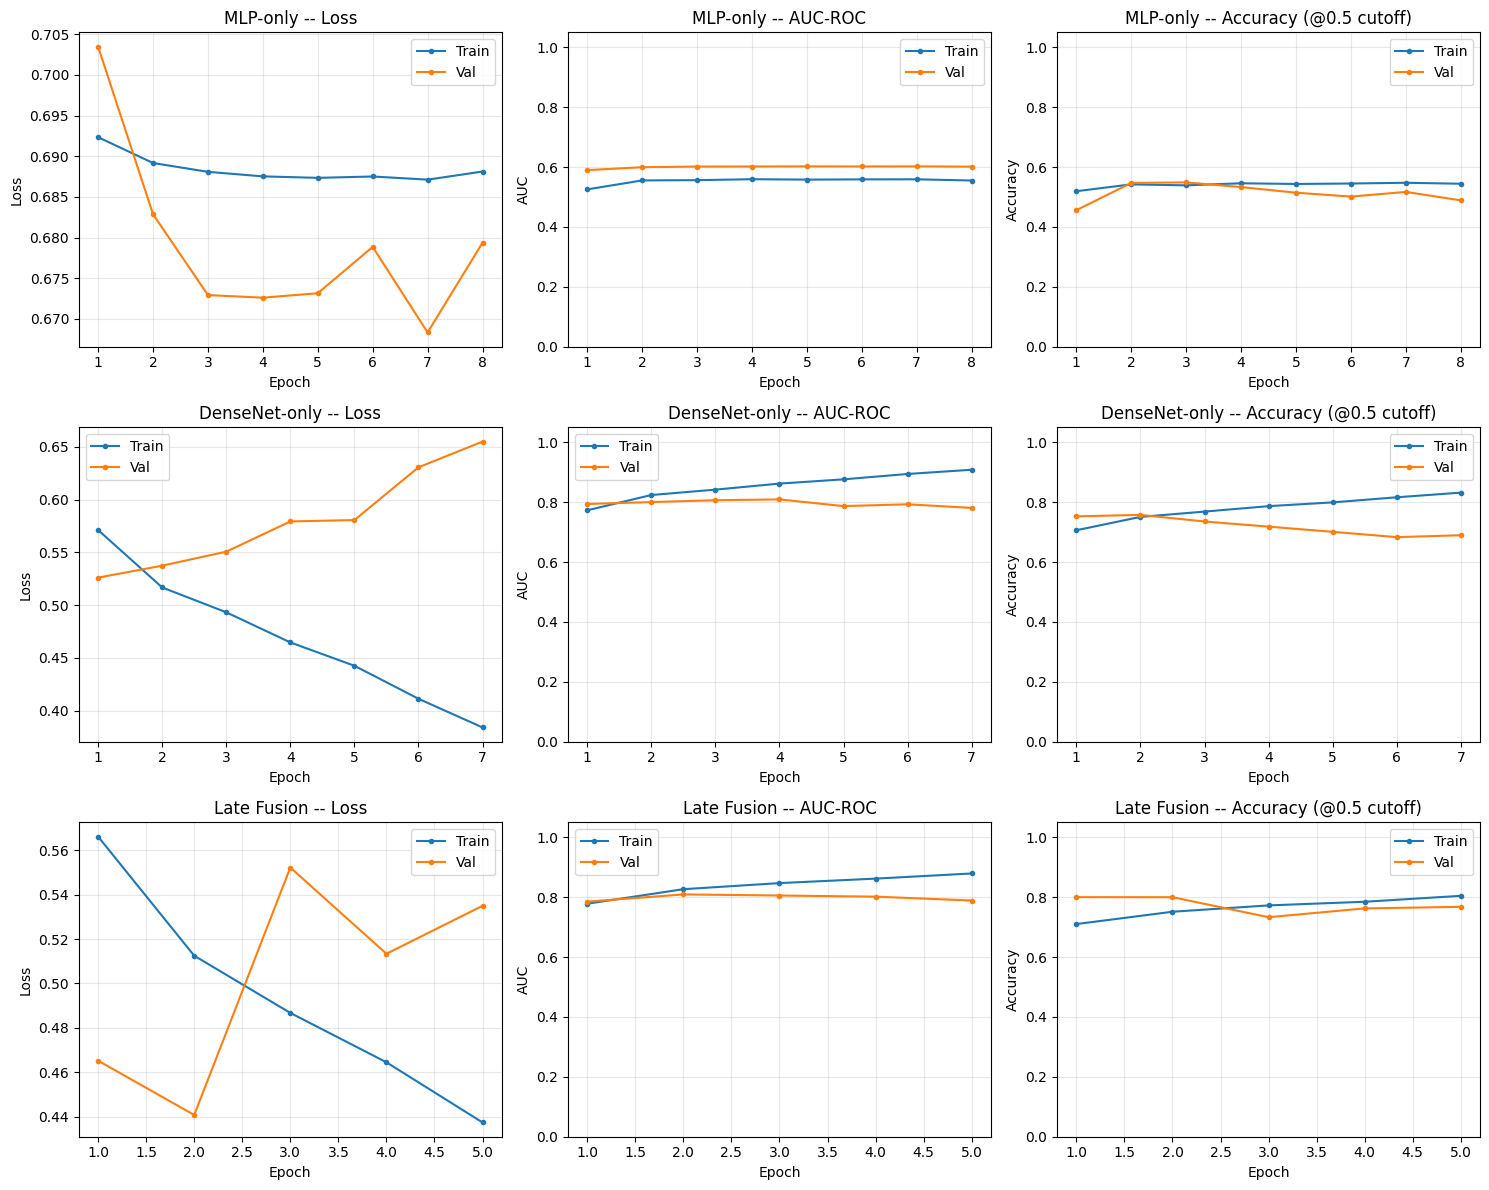

In [13]:
available_hist_models = [n for n in MODEL_REGISTRY if n in training_histories]
missing_hist = [n for n in MODEL_REGISTRY if n not in available_hist_models]
if missing_hist:
    print(f"No epoch history available for: {missing_hist} "
          f"(only produced by a fresh training run in Section 6, not by 6b's checkpoint recovery)")

if available_hist_models:
    fig, axes = plt.subplots(len(available_hist_models), 3,
                              figsize=(15, 4 * len(available_hist_models)), squeeze=False)
    for row, name in enumerate(available_hist_models):
        h = training_histories[name]
        epochs = range(1, len(h["train_loss"]) + 1)

        ax = axes[row][0]
        ax.plot(epochs, h["train_loss"], label="Train", marker="o", markersize=3)
        ax.plot(epochs, h["val_loss"], label="Val", marker="o", markersize=3)
        ax.set_title(f"{name} -- Loss")
        ax.set_xlabel("Epoch"); ax.set_ylabel("Loss"); ax.legend(); ax.grid(alpha=0.3)

        ax = axes[row][1]
        ax.plot(epochs, h["train_auc"], label="Train", marker="o", markersize=3)
        ax.plot(epochs, h["val_auc"], label="Val", marker="o", markersize=3)
        ax.set_title(f"{name} -- AUC-ROC")
        ax.set_xlabel("Epoch"); ax.set_ylabel("AUC"); ax.set_ylim(0, 1.05)
        ax.legend(); ax.grid(alpha=0.3)

        ax = axes[row][2]
        ax.plot(epochs, h["train_acc"], label="Train", marker="o", markersize=3)
        ax.plot(epochs, h["val_acc"], label="Val", marker="o", markersize=3)
        ax.set_title(f"{name} -- Accuracy (@0.5 cutoff)")
        ax.set_xlabel("Epoch"); ax.set_ylabel("Accuracy"); ax.set_ylim(0, 1.05)
        ax.legend(); ax.grid(alpha=0.3)

    plt.tight_layout()
    plt.savefig("training_curves.png", dpi=200, bbox_inches="tight")
    plt.show()
else:
    print("No training history available for any model -- run Section 6 fresh to generate curves.")


## 7. Results table

In [14]:
def _metrics_row(name, r):
    return {
        "Model": name,
        "Threshold": round(r.get("threshold_used", CONFIG["threshold"]), 4),
        "AUC-ROC": round(r["auc"], 4),
        "F1": round(r["f1"], 4),
        "Precision": round(r["precision"], 4),
        "Recall": round(r["recall"], 4),
        "Accuracy": round(r["accuracy"], 4),
        "Sensitivity": round(r["sensitivity"], 4),
        "Specificity": round(r["specificity"], 4),
    }

summary_df = pd.DataFrame([
    {**_metrics_row(name, r), "CPU Latency (ms/batch)": round(r["cpu_latency_ms_per_batch"], 1)}
    for name, r in results.items()
])
summary_df.to_csv("ablation_summary.csv", index=False)
print("Primary operating point -- max specificity (fewest false alarms):")
print(summary_df.to_string(index=False))

if "results_high_sensitivity" in globals() and results_high_sensitivity:
    hs_df = pd.DataFrame([_metrics_row(name, r) for name, r in results_high_sensitivity.items()])
    hs_df.to_csv("ablation_summary_high_sensitivity.csv", index=False)
    print(f"\nHigh-sensitivity operating point (target sensitivity >= {CONFIG['target_sensitivity']:.0%}):")
    print(hs_df.to_string(index=False))

if "results_default_threshold" in globals() and results_default_threshold:
    default_df = pd.DataFrame([_metrics_row(name, r) for name, r in results_default_threshold.items()])
    print("\nFor comparison, fixed threshold=0.5:")
    print(default_df.to_string(index=False))


Primary operating point -- max specificity (fewest false alarms):
        Model  Threshold  AUC-ROC     F1  Precision  Recall  Accuracy  Sensitivity  Specificity  CPU Latency (ms/batch)
     MLP-only     0.5225   0.5652 0.2463     0.1979  0.3261    0.6816       0.3261       0.7491                     0.1
DenseNet-only     0.8505   0.8296 0.5016     0.5607  0.4537    0.8561       0.4537       0.9325                  5431.9
  Late Fusion     0.7697   0.8359 0.5081     0.5957  0.4429    0.8632       0.4429       0.9429                  5398.9

High-sensitivity operating point (target sensitivity >= 80%):
        Model  Threshold  AUC-ROC     F1  Precision  Recall  Accuracy  Sensitivity  Specificity
     MLP-only     0.4674   0.5652 0.2848     0.1770  0.7284    0.4164       0.7284       0.3572
DenseNet-only     0.4307   0.8296 0.4609     0.3188  0.8313    0.6897       0.8313       0.6629
  Late Fusion     0.2217   0.8359 0.4617     0.3169  0.8503    0.6837       0.8503       0.6520

For co

## 8. Ablation comparison — all metrics (computed live from `results`)

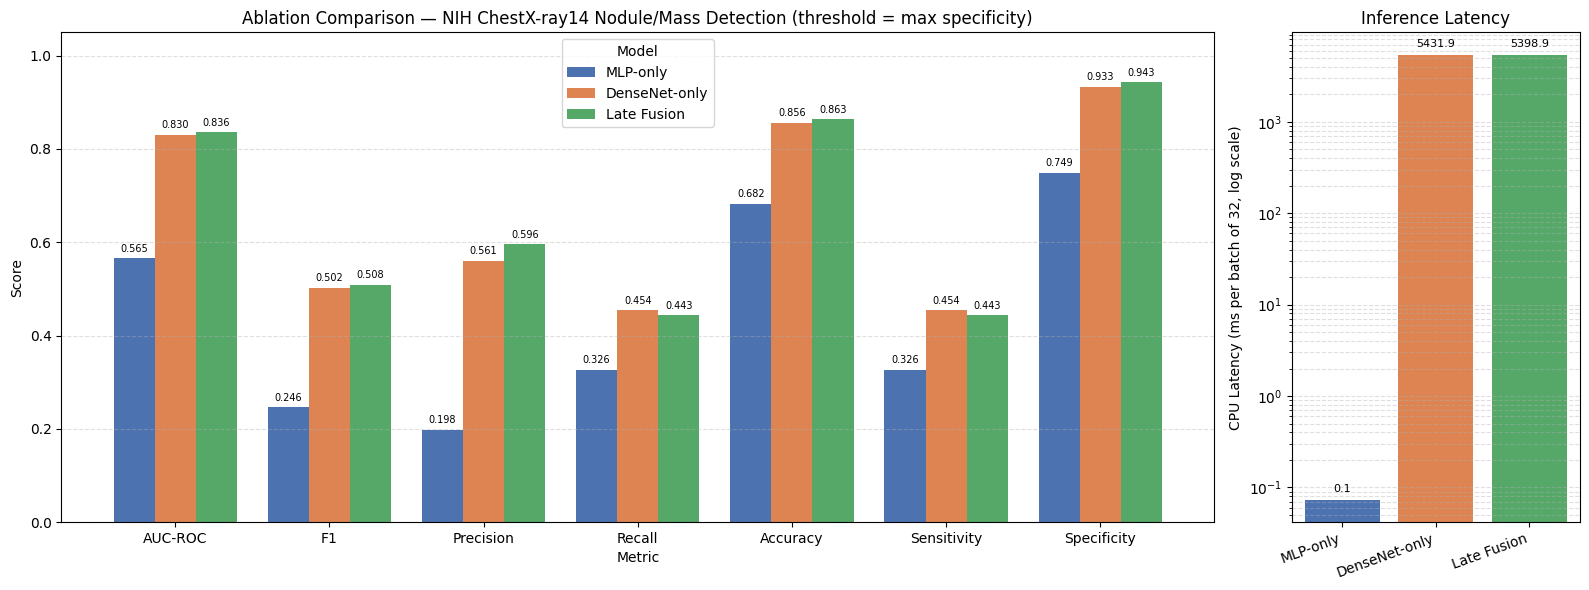

In [15]:
score_metrics = ["AUC-ROC", "F1", "Precision", "Recall", "Accuracy", "Sensitivity", "Specificity"]
metric_keys = ["auc", "f1", "precision", "recall", "accuracy", "sensitivity", "specificity"]
# NEW -- model order and every value below are pulled live from `results`; nothing here
# is typed in, so this always reflects whatever actually ran, not a snapshot from a
# previous session.
model_order = [n for n in MODEL_REGISTRY if n in results]
palette = ["#4C72B0", "#DD8452", "#55A868"]
colors = palette[:len(model_order)]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [4, 1]})

x = np.arange(len(score_metrics))
width = 0.8 / max(len(model_order), 1)
for i, name in enumerate(model_order):
    values = [results[name][k] for k in metric_keys]
    offset = (i - (len(model_order) - 1) / 2) * width
    bars = ax1.bar(x + offset, values, width, label=name, color=colors[i])
    for bar, val in zip(bars, values):
        ax1.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.01,
                  f"{val:.3f}", ha="center", va="bottom", fontsize=7)

ax1.set_xlabel("Metric")
ax1.set_ylabel("Score")
ax1.set_title("Ablation Comparison — NIH ChestX-ray14 Nodule/Mass Detection (threshold = max specificity)")
ax1.set_xticks(x)
ax1.set_xticklabels(score_metrics)
ax1.set_ylim(0, 1.05)
ax1.legend(title="Model")
ax1.grid(axis="y", linestyle="--", alpha=0.4)

latency = [results[n]["cpu_latency_ms_per_batch"] for n in model_order]
x2 = np.arange(len(model_order))
bars2 = ax2.bar(x2, latency, color=colors)
ax2.set_yscale("log")
ax2.set_ylabel(f"CPU Latency (ms per batch of {CONFIG['batch_size']}, log scale)")
ax2.set_title("Inference Latency")
ax2.set_xticks(x2)
ax2.set_xticklabels(model_order, rotation=20, ha="right")
for bar, val in zip(bars2, latency):
    ax2.text(bar.get_x() + bar.get_width() / 2, bar.get_height() * 1.15,
              f"{val:.1f}", ha="center", va="bottom", fontsize=8)
ax2.grid(axis="y", linestyle="--", alpha=0.4, which="both")

plt.tight_layout()
plt.savefig("ablation_all_metrics_comparison.png", dpi=300, bbox_inches="tight")
plt.show()


## 9. ROC overlay

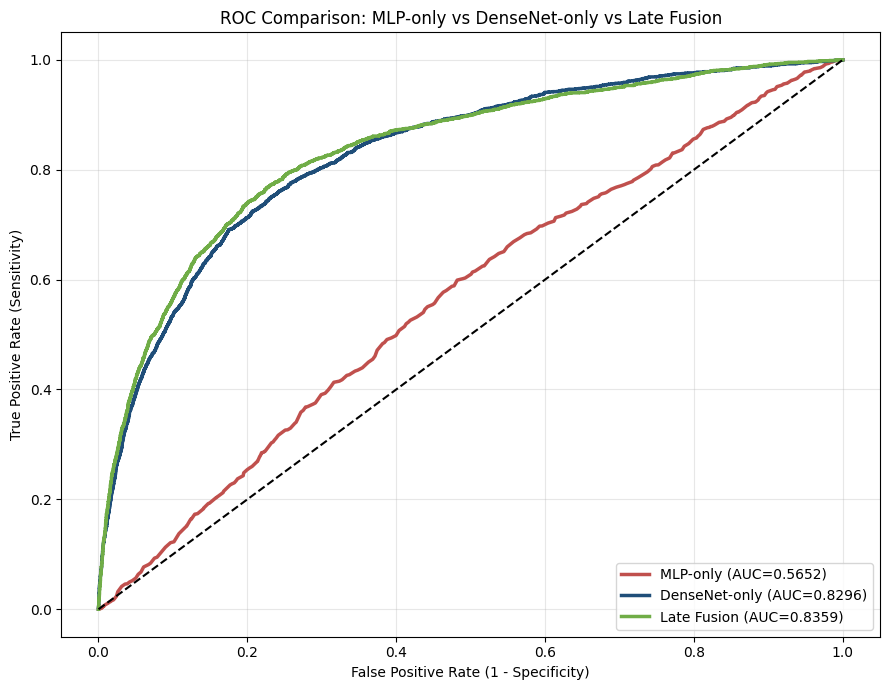

In [16]:
plt.figure(figsize=(9, 7))
colors = ["#c0504d", "#1f4e79", "#70ad47"]
for (name, r), color in zip(results.items(), colors):
    fpr, tpr, _ = roc_curve(r["raw_labels"], r["raw_preds"])
    plt.plot(fpr, tpr, lw=2.5, color=color, label=f"{name} (AUC={r['auc']:.4f})")

plt.plot([0, 1], [0, 1], "k--", lw=1.5)
plt.xlabel("False Positive Rate (1 - Specificity)")
plt.ylabel("True Positive Rate (Sensitivity)")
plt.title("ROC Comparison: MLP-only vs DenseNet-only vs Late Fusion")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("ablation_roc_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

## 10. Confusion matrices, side by side

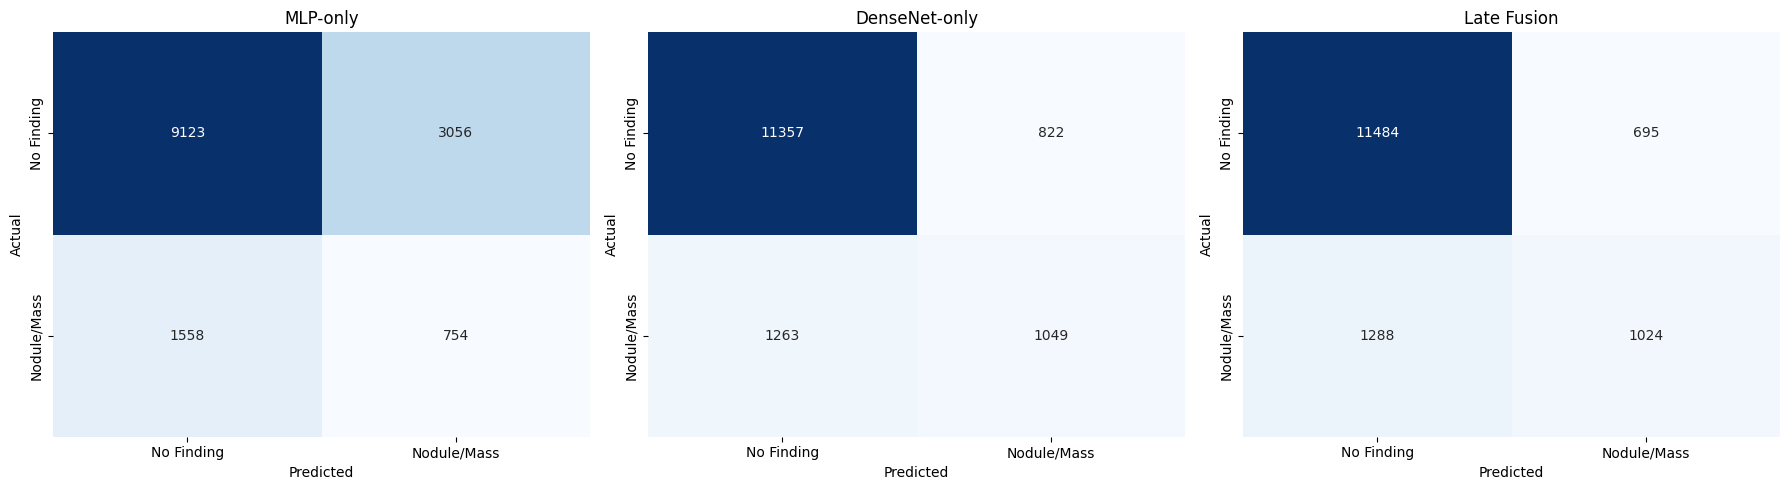

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (name, r) in zip(axes, results.items()):
    sns.heatmap(np.array(r["confusion_matrix"]), annot=True, fmt="d", cmap="Blues",
                xticklabels=["No Finding", "Nodule/Mass"],
                yticklabels=["No Finding", "Nodule/Mass"], ax=ax, cbar=False)
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.savefig("ablation_confusion_matrices.png", dpi=300, bbox_inches="tight")
plt.show()

## 11. Grad-CAM++ visual comparison

In [18]:
class GradCAMPlusPlus:
    """Grad-CAM++ (Chattopadhay et al., 2018) for a single target conv layer."""
    def __init__(self, model, target_layer):
        self.model = model
        self.activations = None
        self.gradients = None
        target_layer.register_forward_hook(self._save_activation)
        target_layer.register_full_backward_hook(self._save_gradient)

    def _save_activation(self, module, inp, out):
        self.activations = out.detach()

    def _save_gradient(self, module, grad_in, grad_out):
        self.gradients = grad_out[0].detach()

    def generate(self, image, metadata):
        """image, metadata: single-sample batches (B=1). Returns an (H, W) CAM in [0, 1]."""
        self.model.zero_grad()
        logit = self.model(image, metadata)   # single BCE logit, natural Grad-CAM target
        logit.sum().backward()

        grads = self.gradients        # (1, C, H, W)
        activations = self.activations  # (1, C, H, W)
        eps = 1e-8

        grads_2 = grads ** 2
        grads_3 = grads ** 3
        sum_activations = activations.sum(dim=(2, 3), keepdim=True)

        alpha_denom = 2 * grads_2 + sum_activations * grads_3
        alpha_denom = torch.where(alpha_denom != 0, alpha_denom, torch.ones_like(alpha_denom))
        alphas = grads_2 / (alpha_denom + eps)

        weights = (alphas * torch.relu(grads)).sum(dim=(2, 3))          # (1, C)
        cam = torch.relu((weights[:, :, None, None] * activations).sum(dim=1))  # (1, H, W)
        cam = cam.squeeze(0)

        cam = cam - cam.min()
        cam = cam / (cam.max() + eps)
        return cam.cpu().numpy()


def get_target_layer(model):
    """Last conv of the final dense block -- same target used for DenseNet-121 Grad-CAM
    in the reference deck."""
    return model.vision_branch.features.denseblock4.denselayer16.conv2


def denormalize(img_tensor):
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
    img = img_tensor.cpu() * std + mean
    return img.clamp(0, 1).permute(1, 2, 0).numpy()


def overlay_heatmap(img_rgb, cam, alpha=0.45):
    h, w = img_rgb.shape[:2]
    cam_resized = np.array(Image.fromarray(cam.astype(np.float32)).resize((w, h), resample=Image.BILINEAR))
    heatmap = plt.cm.jet(cam_resized)[..., :3]
    overlay = np.clip((1 - alpha) * img_rgb + alpha * heatmap, 0, 1)
    return overlay

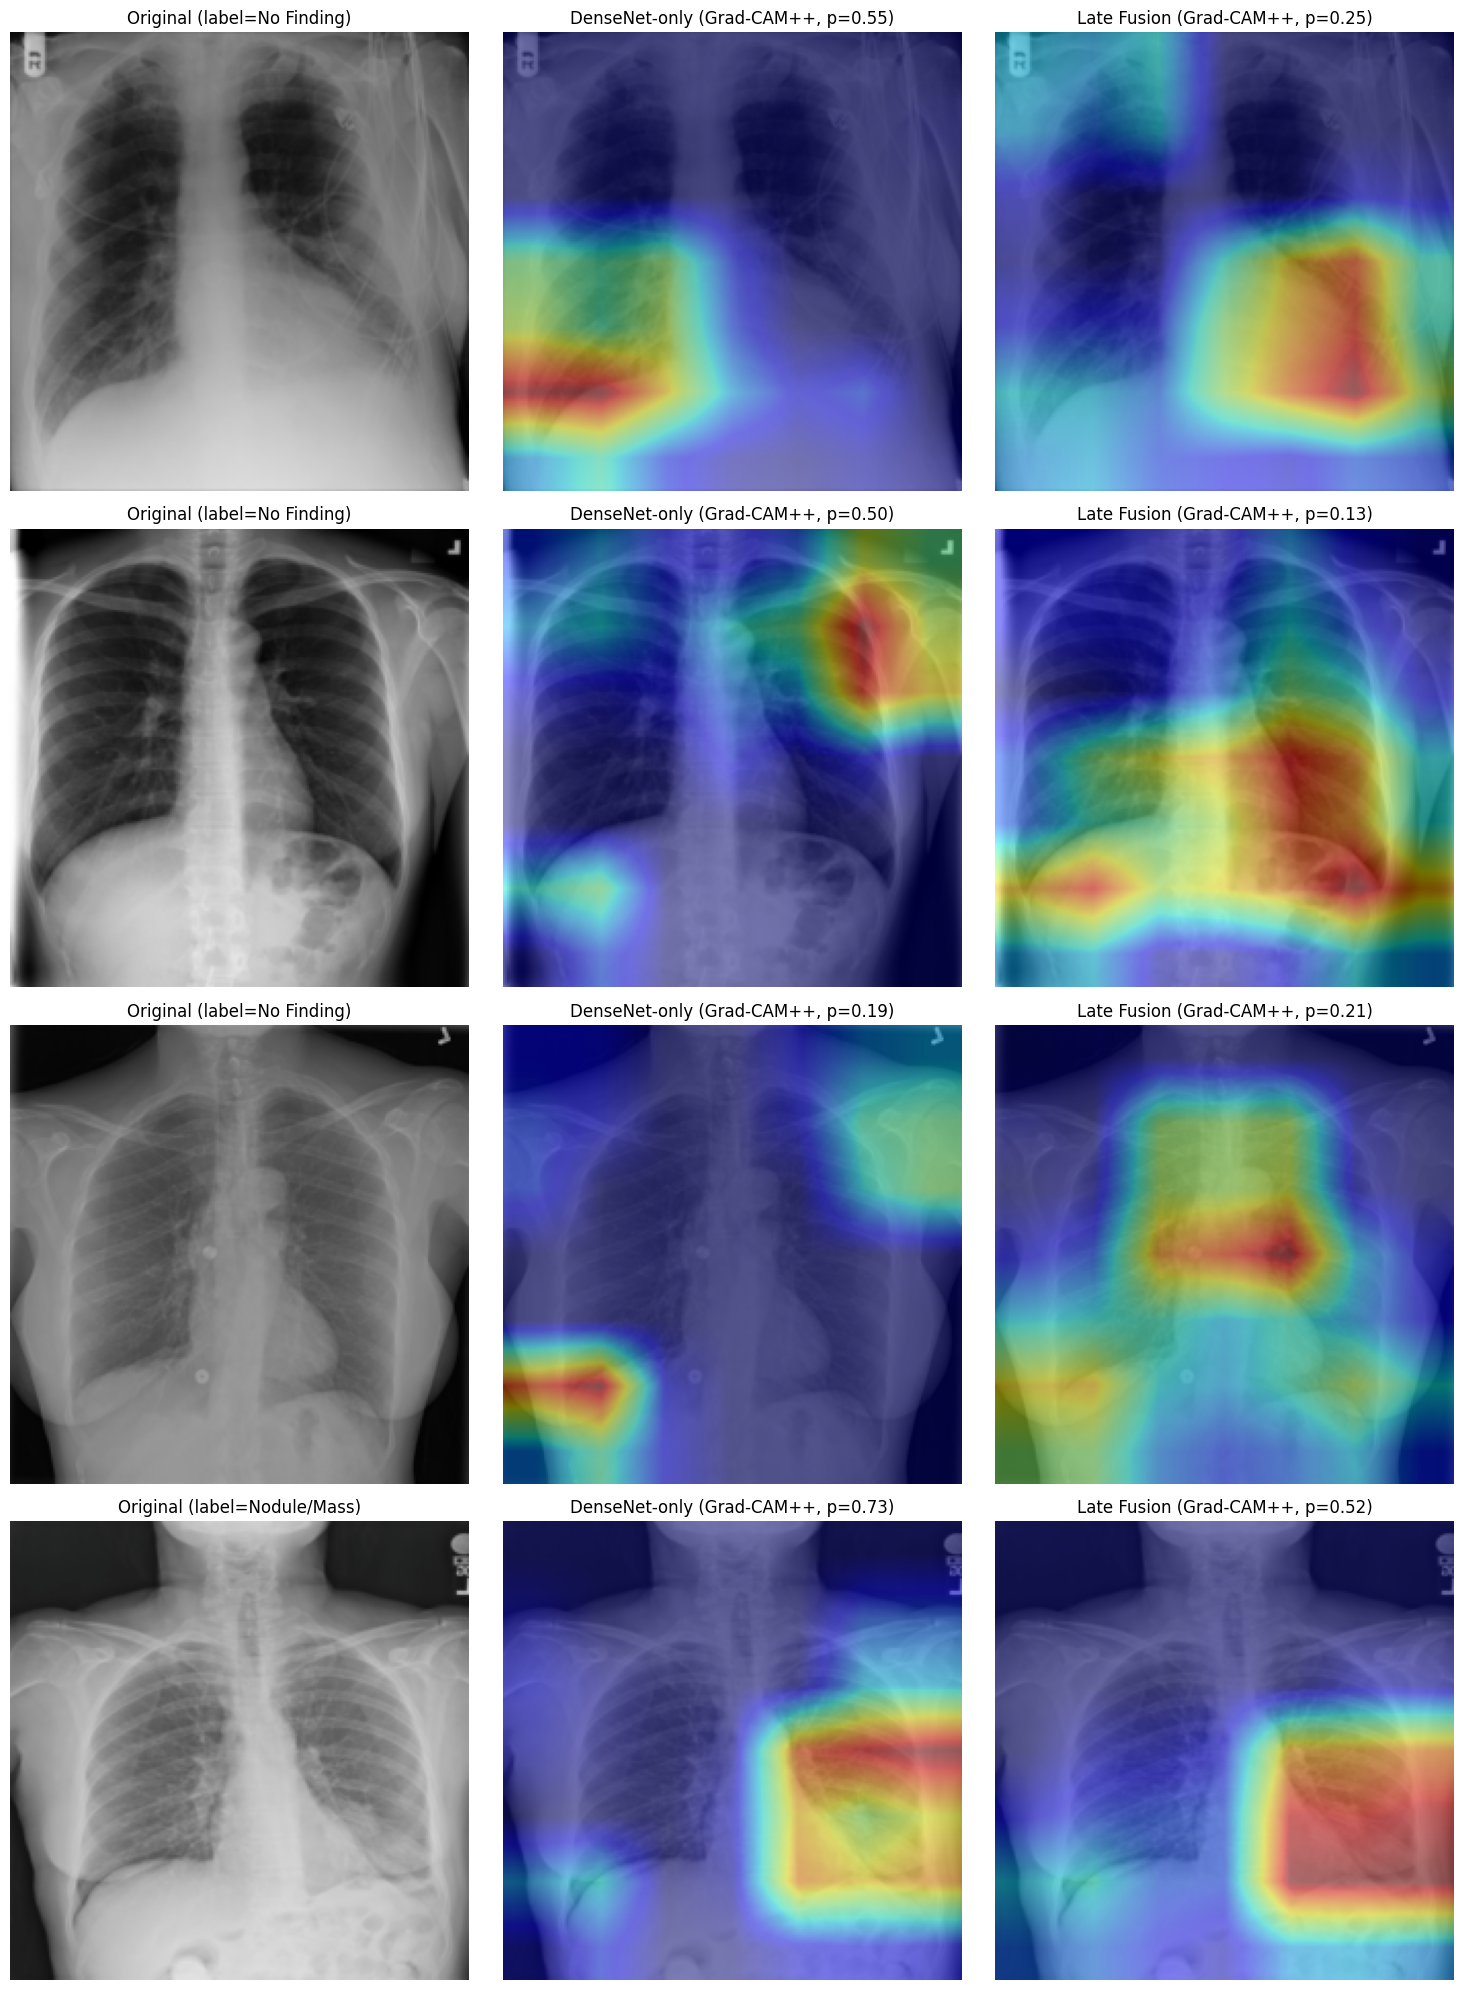

In [20]:
N_SAMPLES = 4  # number of test images to visualize

gradcam_targets = {}
for name in ["DenseNet-only", "Late Fusion"]:
    if name in trained_models:
        trained_models[name] = trained_models[name].to(DEVICE)
        gradcam_targets[name] = (trained_models[name], get_target_layer(trained_models[name]))

# Rebuild the (unshuffled) test dataset directly -- test_ds itself isn't returned by
# build_loaders, only the DataLoader wrapping it, and here we need indexed single-sample access.
_, eval_tfms = build_transforms(CONFIG["img_size"])
test_ds = NIHMultimodalDataset(test_df, eval_tfms, age_stats)

sample_indices = np.random.RandomState(SEED).choice(len(test_df), size=N_SAMPLES, replace=False)

fig, axes = plt.subplots(N_SAMPLES, 1 + len(gradcam_targets), figsize=(5 * (1 + len(gradcam_targets)), 5 * N_SAMPLES))
if N_SAMPLES == 1:
    axes = axes[None, :]

for row, idx in enumerate(sample_indices):
    image, metadata, label = test_ds[idx]
    img_batch = image.unsqueeze(0).to(DEVICE)
    meta_batch = metadata.unsqueeze(0).to(DEVICE)
    img_rgb = denormalize(image)

    axes[row, 0].imshow(img_rgb)
    axes[row, 0].set_title(f"Original (label={'Nodule/Mass' if label==1 else 'No Finding'})")
    axes[row, 0].axis("off")

    for col, (name, (model, target_layer)) in enumerate(gradcam_targets.items(), start=1):
        model.eval()  # disable dropout so the CAM isn't noisy, gradients still flow fine in eval mode
        cam_engine = GradCAMPlusPlus(model, target_layer)
        cam = cam_engine.generate(img_batch, meta_batch)
        overlay = overlay_heatmap(img_rgb, cam)

        with torch.no_grad():
            prob = torch.sigmoid(model(img_batch, meta_batch)).item()

        axes[row, col].imshow(overlay)
        axes[row, col].set_title(f"{name} (Grad-CAM++, p={prob:.2f})")
        axes[row, col].axis("off")

plt.tight_layout()
plt.savefig("gradcam_plusplus_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

# Release these models back to CPU now that Grad-CAM is done -- Section 12's
# multi-seed loop trains fresh models per seed and does not need these held on GPU.
for name in list(trained_models.keys()):
    trained_models[name] = trained_models[name].to("cpu")
gc.collect()
if DEVICE.type == "cuda":
    torch.cuda.empty_cache()